# **Практическая работа №7. Применение методов машинного обучения для решения задач классификации текстов. Метод Наивного Байеса. Метод опорных векторов**

## Задание 0. Найдите в глобальной сети или соберите свой датасет для классификации текстов (Пример: новости -> рубрики, комментарии в соц. сетях -> характер, )

* Количество классов в датасете должно превышать 2
* Язык текста в датасете: русский

- ### Пример датасетов: [Russian Texts](https://www.kaggle.com/datasets?search=text+classification+russian)

### Загрузите датасет

In [1]:
import pandas as pd

df = pd.read_csv("sentiment_dataset.csv")

print(df.shape)
print(df["label"].value_counts())
df.head()

(290458, 3)
label
2    96992
1    96877
0    96589
Name: count, dtype: int64


,text,label,src
0,"Пальто красивое, но пришло с дырой в молнии. П...",0,rureviews
1,"Очень долго шел заказ,ждала к новому году,приш...",0,rureviews
2,"Могу сказать одно, брюки нормальные, НО они бы...",0,rureviews
3,"Доставка быстрая, меньше месяца. Заказывали ра...",0,rureviews
4,Мне не очень понравилось это платье. Размер ...,0,rureviews


### Разделите данные на обучающую и валидационную выборки

In [2]:
from sklearn.model_selection import train_test_split

a = df.groupby("label", group_keys=False).sample(n=10000)

X = a["text"].fillna("")
y = a["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y
)

print(X_train.shape, X_test.shape)

(24000,) (6000,)


### При выполении дальнейших заданий поэксперементируйте с методами векторизации текста:


1. [Bag of Words](https://habr.com/ru/companies/mlclass/articles/270591/) (BOW): Bag of Words представляет текст как вектор, где каждый элемент обозначает количество вхождений конкретного слова в тексте. Процесс включает в себя создание словаря всех уникальных слов в корпусе текстов и подсчет частоты встречаемости каждого слова в отдельных текстах.

2. [TF-IDF](https://habr.com/ru/companies/otus/articles/755772/) (Term Frequency-Inverse Document Frequency): TF-IDF учитывает не только количество вхождений слова в текст, но и частоту его встречаемости в других текстах. Он вычисляет вес слова, умножая его частоту встречаемости (term frequency) на обратную частоту документа (inverse document frequency). Это позволяет снизить вес наиболее часто встречающихся слов, которые могут быть менее информативными.

3. Word Embeddings (например, [Word2Vec](https://habr.com/ru/articles/446530/) и [GloVe](https://jonathan-hui.medium.com/nlp-word-embedding-glove-5e7f523999f6)): Word Embeddings используют нейронные сети для создания векторных представлений слов, которые учитывают семантическую близость между словами. Нейронные сети обучаются на больших текстовых корпусах и захватывают семантические отношения между словами, что позволяет представить слова в векторном пространстве.

4. One-Hot Encoding: One-Hot Encoding преобразует каждое слово в уникальный вектор, где все элементы равны нулю, за исключением одного, который равен единице. Каждый вектор соответствует отдельному слову и используется для представления его в пространстве признаков.

5. [Count Vectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html): Count Vectorizer подсчитывает количество раз, которое каждое слово встречается в тексте. Он создает вектор, в котором каждый элемент соответствует количеству вхождений конкретного слова в текст.

6. [Hashing Vectorizer](https://kavita-ganesan.com/hashingvectorizer-vs-countvectorizer/): Hashing Vectorizer преобразует каждое слово в уникальный числовой идентификатор с помощью хеширования. Он использует хеш-функцию для преобразования слова в числовое значение, которое затем используется в векторном представлении.

7. [Doc2Vec](https://habr.com/ru/articles/599513/): Doc2Vec является расширением метода Word2Vec и позволяет получить векторное представление не только отдельных слов, но и целых документов или текстов. Алгоритм обучает нейронную сеть, которая учитывает контекст и порядок слов в предложении, чтобы получить векторное представление документа. Это позволяет сравнивать и измерять семантическую близость между целыми текстовыми документами.

#### Оцените влияние разных методов на конечный результат

## Задание 1. Обучите модель классификатора Naive Bayes для решения поставленной задачи, используя пайплайн и подбор оптимальных параметров

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import GridSearchCV

a = Pipeline([
    ("vectorizer", TfidfVectorizer(max_features=20000)),
    ("model", MultinomialNB())
])

params = [
    {
        "vectorizer": [CountVectorizer(max_features=20000)],
        "vectorizer__ngram_range": [(1, 1), (1, 2)],
        "model__alpha": [0.5, 1]
    },
    {
        "vectorizer": [TfidfVectorizer(max_features=20000)],
        "vectorizer__ngram_range": [(1, 1), (1, 2)],
        "model__alpha": [0.5, 1]
    }
]

nb_search = GridSearchCV(
    a,
    params,
    cv=3,
    scoring="accuracy",
    n_jobs=1
)

nb_search.fit(X_train, y_train)

nb_model = nb_search.best_estimator_

print(nb_search.best_params_)
print("CV accuracy:", nb_search.best_score_)

{'model__alpha': 1, 'vectorizer': CountVectorizer(max_features=20000), 'vectorizer__ngram_range': (1, 2)}
CV accuracy: 0.6668333333333334


### Вывод матрицы ошибок:

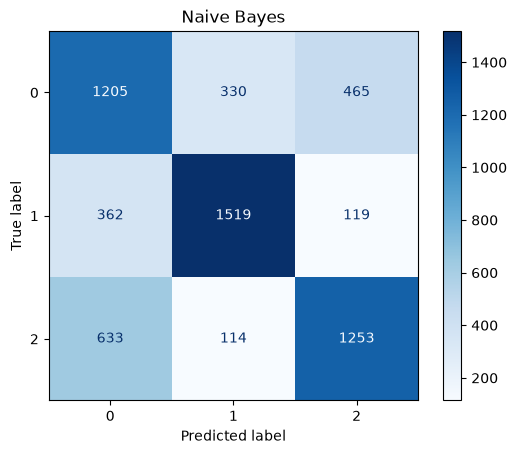

In [4]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

a = nb_model.predict(X_test)

ConfusionMatrixDisplay.from_predictions(y_test, a, cmap="Blues")
plt.title("Naive Bayes")
plt.show()

### Оценка точности:

In [5]:
from sklearn.metrics import accuracy_score, classification_report

nb_pred = nb_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, nb_pred))
print(classification_report(y_test, nb_pred))

Accuracy: 0.6628333333333334
              precision    recall  f1-score   support

           0       0.55      0.60      0.57      2000
           1       0.77      0.76      0.77      2000
           2       0.68      0.63      0.65      2000

    accuracy                           0.66      6000
   macro avg       0.67      0.66      0.66      6000
weighted avg       0.67      0.66      0.66      6000



## Задание 2. Обучите модель SVM (метод опорных векторов) для решения поставленной задачи, используя пайплайны и подбор оптимальных параметров

In [19]:
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import GridSearchCV

a = Pipeline([
    ("vectorizer", TfidfVectorizer(max_features=10000)),
    ("model", LinearSVC(max_iter=10000))
])

params = [
    {
        "vectorizer": [CountVectorizer(max_features=10000)],
        "model__C": [0.5, 1]
    },
    {
        "vectorizer": [TfidfVectorizer(max_features=10000)],
        "model__C": [0.5, 1]
    }
]

svm_search = GridSearchCV(
    a,
    params,
    cv=3,
    scoring="accuracy",
    n_jobs=1
)

svm_search.fit(X_train, y_train)

svm_model = svm_search.best_estimator_

print(svm_search.best_params_)
print("CV accuracy:", svm_search.best_score_)

{'model__C': 0.5, 'vectorizer': TfidfVectorizer(max_features=10000)}
CV accuracy: 0.6459166666666667


### Вывод матрицы ошибок:

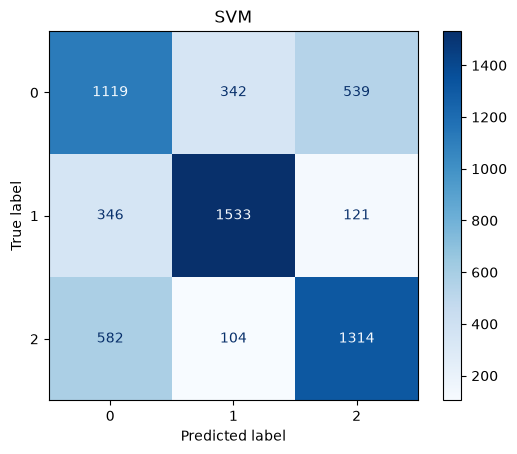

In [7]:
svm_pred = svm_model.predict(X_test)

ConfusionMatrixDisplay.from_predictions(y_test, svm_pred, cmap="Blues")
plt.title("SVM")
plt.show()

### Оценка точности:

In [8]:
print("Accuracy:", accuracy_score(y_test, svm_pred))
print(classification_report(y_test, svm_pred))

Accuracy: 0.661
              precision    recall  f1-score   support

           0       0.55      0.56      0.55      2000
           1       0.77      0.77      0.77      2000
           2       0.67      0.66      0.66      2000

    accuracy                           0.66      6000
   macro avg       0.66      0.66      0.66      6000
weighted avg       0.66      0.66      0.66      6000



## Задание 3. Обучите модель классификатора Decision Tree Classifier для решения поставленной задачи

In [9]:
from sklearn.tree import DecisionTreeClassifier

tree_model = Pipeline([
    ("vectorizer", TfidfVectorizer(max_features=10000)),
    ("model", DecisionTreeClassifier(max_depth=30, min_samples_leaf=3))
])

tree_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('vectorizer', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",10000
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None


### Вывод матрицы ошибок:

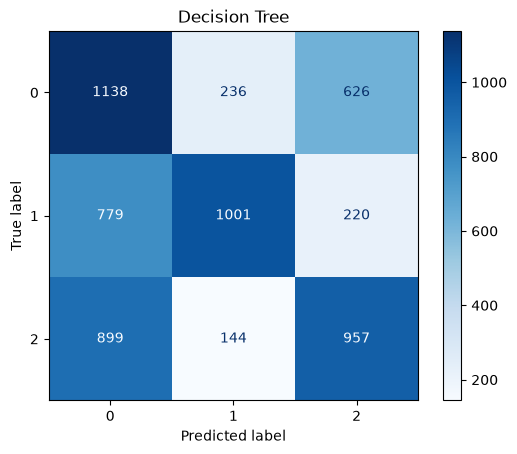

In [10]:
tree_pred = tree_model.predict(X_test)

ConfusionMatrixDisplay.from_predictions(y_test, tree_pred, cmap="Blues")
plt.title("Decision Tree")
plt.show()

### Оценка точности:

In [11]:
print("Accuracy:", accuracy_score(y_test, tree_pred))
print(classification_report(y_test, tree_pred))

Accuracy: 0.516
              precision    recall  f1-score   support

           0       0.40      0.57      0.47      2000
           1       0.72      0.50      0.59      2000
           2       0.53      0.48      0.50      2000

    accuracy                           0.52      6000
   macro avg       0.55      0.52      0.52      6000
weighted avg       0.55      0.52      0.52      6000



## Задание 4. Обучите модель классификатора Random Forest Classifier для решения поставленной задачи

In [12]:
from sklearn.ensemble import RandomForestClassifier

forest_model = Pipeline([
    ("vectorizer", TfidfVectorizer(max_features=10000)),
    ("model", RandomForestClassifier(
        n_estimators=150,
        max_depth=30,
        min_samples_leaf=2,
        n_jobs=1
    ))
])

forest_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('vectorizer', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",10000
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None


### Вывод матрицы ошибок:

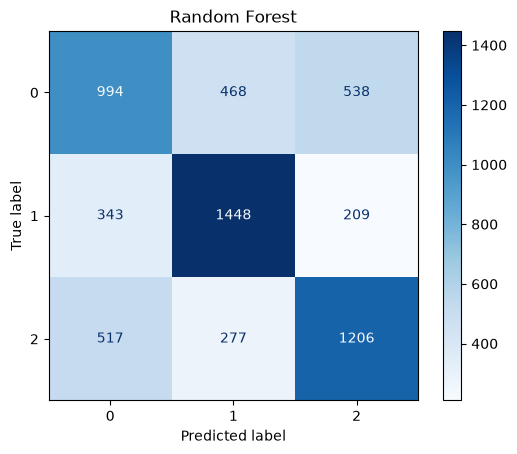

In [18]:
forest_pred = forest_model.predict(X_test)

ConfusionMatrixDisplay.from_predictions(y_test, forest_pred, cmap="Blues")
plt.title("Random Forest")
plt.show()

### Оценка точности:

In [17]:
print("Accuracy:", accuracy_score(y_test, forest_pred))
print(classification_report(y_test, forest_pred))

Accuracy: 0.608
              precision    recall  f1-score   support

           0       0.54      0.50      0.52      2000
           1       0.66      0.72      0.69      2000
           2       0.62      0.60      0.61      2000

    accuracy                           0.61      6000
   macro avg       0.60      0.61      0.61      6000
weighted avg       0.60      0.61      0.61      6000



## Подведите общие итоги и сделайте выводы

In [16]:
results = pd.DataFrame({
    "Модель": [
        "Naive Bayes",
        "SVM",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, nb_pred),
        accuracy_score(y_test, svm_pred),
        accuracy_score(y_test, tree_pred),
        accuracy_score(y_test, forest_pred)
    ]
})

results = results.sort_values("Accuracy", ascending=False)

display(results)

print("Лучшая модель:", results.iloc[0]["Модель"])

print()
print("Для Naive Bayes лучший способ векторизации:")
print(type(nb_model.named_steps["vectorizer"]).__name__)

print("Для SVM лучший способ векторизации:")
print(type(svm_model.named_steps["vectorizer"]).__name__)

,Модель,Accuracy
0,Naive Bayes,0.662833
1,SVM,0.661000
3,Random Forest,0.608000
2,Decision Tree,0.516000


Лучшая модель: Naive Bayes

Для Naive Bayes лучший способ векторизации:
CountVectorizer
Для SVM лучший способ векторизации:
TfidfVectorizer


В работе были сравнены четыре алгоритма классификации текстов: Naive Bayes, SVM, Decision Tree и Random Forest. Для Naive Bayes и SVM дополнительно сравниваются Bag of Words и TF-IDF. Итоговая таблица выше показывает точность каждой модели; лучшей считается модель с максимальным Accuracy. Для текстовых данных обычно лучше работают методы, рассчитанные на большое разреженное пространство признаков, поэтому SVM и Naive Bayes часто оказываются сильнее одиночного дерева.